# Network

Validation of `snnrl.network`.

- Input: 40 Poisson inputs at 40 Hz
- Recurrent: 50 LIF and 50 ALIF neurons, all-to-all connections without self-connections
- Output: 2 leaky readouts

In [1]:
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt

from snnrl.inputs import poisson_spikes
from snnrl.network import init_weights, make_network_params, run
from snnrl.neuron import make_params

In [2]:
N_LIF = 50
N_ALIF = 50
N_IN = 40
N_OUT = 2
N_REC = N_LIF + N_ALIF

SEED = 0

main_key = jax.random.PRNGKey(SEED)
key_weights, key_input = jax.random.split(main_key)

params = make_network_params(make_params(n_lif=N_LIF, n_alif=N_ALIF))
weights = init_weights(key_weights, n_in=N_IN, n_out=N_OUT, params=params)

## 1. Structure

Weight distributions (after initialization)

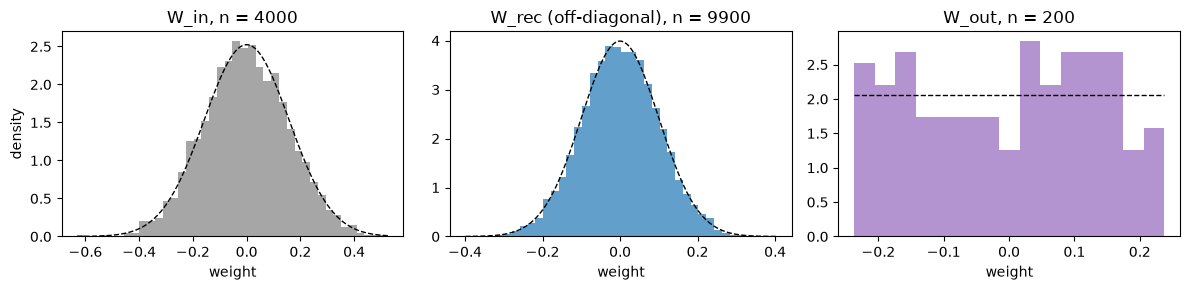

In [3]:
off_diagonal = params.rec_mask > 0
panels = [
    ("W_in", weights.w_in.ravel(), "normal", 1 / jnp.sqrt(N_IN)),
    ("W_rec (off-diagonal)", weights.w_rec[off_diagonal], "normal", 1 / jnp.sqrt(N_REC)),
    ("W_out", weights.w_out.ravel(), "uniform", jnp.sqrt(6 / (N_REC + N_OUT))),
]

w_in = weights.w_in.ravel()
w_rec = weights.w_rec[off_diagonal]
w_out = weights.w_out.ravel()

def plot_normal(ax, w, n):
    scale = 1 / jnp.sqrt(n)
    grid = jnp.linspace(w.min(), w.max(), 200)
    density = jnp.exp(-grid**2 / (2 * scale**2)) / (scale * jnp.sqrt(2 * jnp.pi))
    ax.plot(grid, density, "k--", lw=1)

def plot_uniform(ax, w, n):
    scale = jnp.sqrt(6 / n)
    grid = jnp.linspace(w.min(), w.max(), 200)
    density = jnp.full_like(grid, 1 / (2 * scale))
    ax.plot(grid, density, "k--", lw=1)

fig, axes = plt.subplots(1, 3, figsize=(12, 3))

# W_in
axes[0].hist(w_in, bins=40, density=True, alpha=0.7, color='gray');
axes[0].set_title(f"W_in, n = {w_in.size}")
plot_normal(axes[0], w_in, N_IN)

# W_rec (off-diagonal)
axes[1].hist(w_rec, bins=40, density=True, alpha=0.7);
axes[1].set_title(f"W_rec (off-diagonal), n = {w_rec.size}")
plot_normal(axes[1], w_rec, N_REC)

# W_out
axes[2].hist(w_out, bins=15, density=True, alpha=0.7, color='C4');
axes[2].set_title(f"W_out, n = {w_out.size}")
plot_uniform(axes[2], w_out, N_REC + N_OUT)

axes[0].set_ylabel("density")
for ax in axes:
    ax.set_xlabel("weight")

plt.tight_layout()

Connectivity matrix of the recurrent layer

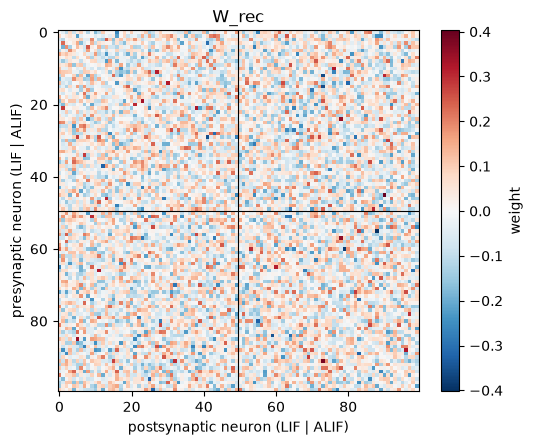

In [4]:
limit = float(jnp.abs(weights.w_rec).max())
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(weights.w_rec, cmap="RdBu_r", vmin=-limit, vmax=limit)

ax.axhline(N_LIF - 0.5, color="k", lw=0.8)
ax.axvline(N_LIF - 0.5, color="k", lw=0.8)

ax.set_xlabel("postsynaptic neuron (LIF | ALIF)")
ax.set_ylabel("presynaptic neuron (LIF | ALIF)")
ax.set_title("W_rec")
plt.colorbar(im, ax=ax, label="weight")
plt.tight_layout()

## 2. Activity

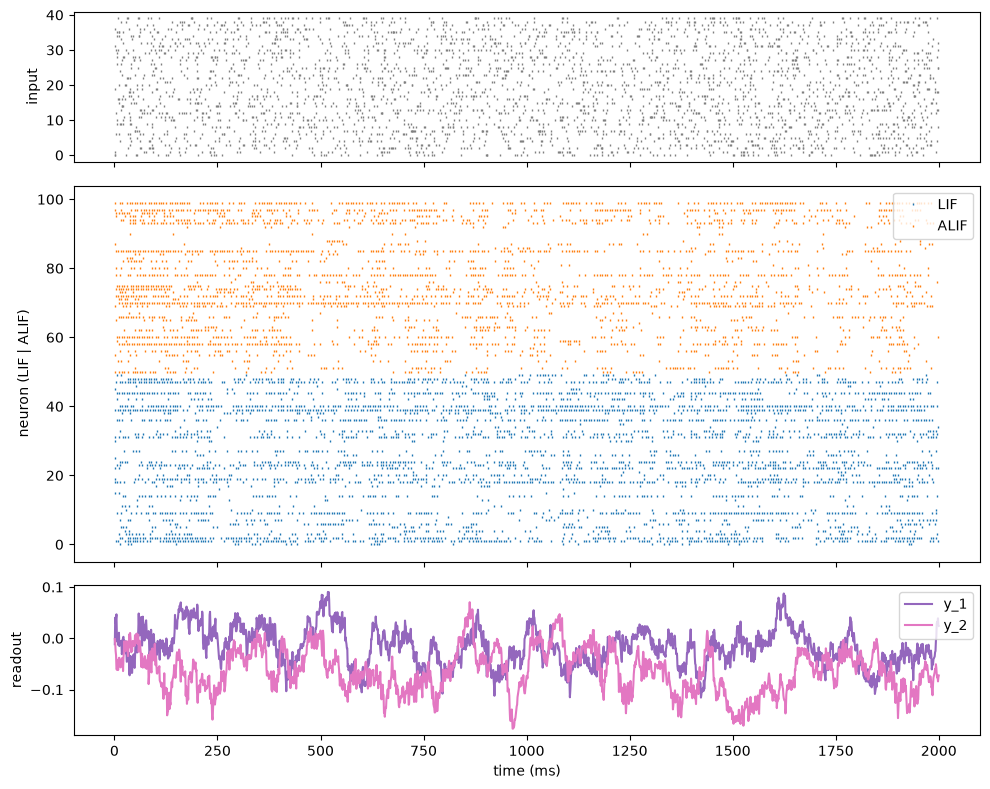

In [5]:
T = 2000 # ms

x = poisson_spikes(key_input, jnp.full((T, N_IN), 40.0))
_, history, y = run(x, weights, params)
z = history.neuron.z
t = jnp.arange(1, T + 1)

fig, axes = plt.subplots(3, 1, figsize=(10, 8), sharex=True,
                         gridspec_kw={"height_ratios": [1, 2.5, 1]})
nrn_idx, spike_times = jnp.nonzero(x.T)
axes[0].plot(spike_times + 1, nrn_idx, "|", color="gray", ms=2)
axes[0].set_ylabel("input")

nrn_idx, spike_times = jnp.nonzero(z.T)
is_alif = params.neuron.is_alif[nrn_idx]
axes[1].plot(spike_times[~is_alif] + 1, nrn_idx[~is_alif], "|", color="C0", ms=2, label="LIF")
axes[1].plot(spike_times[is_alif] + 1, nrn_idx[is_alif], "|", color="C1", ms=2, label="ALIF")
axes[1].set_ylabel("neuron (LIF | ALIF)")
axes[1].legend(loc="upper right")


axes[2].plot(t, y[:, 0], label="y_1", color="C4")
axes[2].plot(t, y[:, 1], label="y_2", color="C6")
axes[2].set_ylabel("readout")
axes[2].set_xlabel("time (ms)")
axes[2].legend(loc="upper right")
plt.tight_layout()

## Firing rates

LIF : mean  37.9 Hz, median  29.5 Hz, silent 4, above 100 Hz 2
ALIF: mean  29.0 Hz, median  21.8 Hz, silent 8, above 100 Hz 1
all : mean  33.4 Hz, median  24.5 Hz, silent 12, above 100 Hz 3


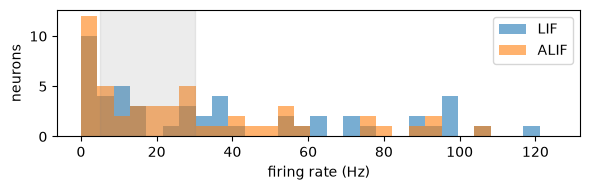

In [6]:
rates = z.mean(0) * 1000 # Hz
is_alif = params.neuron.is_alif
bins = jnp.linspace(0, float(rates.max()) + 5, 30)

lif_rates = rates[~is_alif]
alif_rates = rates[is_alif]

fig, ax = plt.subplots(figsize=(6, 2))
ax.hist(rates[~is_alif], bins=bins, alpha=0.6, label="LIF")
ax.hist(rates[is_alif], bins=bins, alpha=0.6, label="ALIF")
ax.axvspan(5, 30, color="gray", alpha=0.15)
ax.set_xlabel("firing rate (Hz)")
ax.set_ylabel("neurons")
ax.legend()
fig.tight_layout()

for name, r in [("LIF", lif_rates), ("ALIF", alif_rates), ("all", rates)]:
    print(f"{name:4s}: mean {float(r.mean()):5.1f} Hz, median {float(jnp.median(r)):5.1f} Hz, "
          f"silent {int((r == 0).sum())}, above 100 Hz {int((r > 100).sum())}")